In [1]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

bundle = joblib.load("../models/lightgbm_final.joblib")
model, features, cat_cols = bundle["model"], bundle["features"], bundle["cat_cols"]

df = pd.read_csv("../data/processed/features_v2.csv", parse_dates=["date"])
df["target"] = np.log1p(df["market_value_in_eur"])
trainval = df[df["date"] < "2025-01-01"]
test = df[df["date"] >= "2025-01-01"].copy()

# Rebuilding the same category lists as in notebook 03 so the encoding matches the saved model
cat_types = {c: pd.CategoricalDtype(sorted(trainval[c].dropna().unique())) for c in cat_cols}
Xte = test[features].copy()
for c in cat_cols:
    Xte[c] = Xte[c].astype(cat_types[c])

# Computing predictions once; every analysis below reuses these columns
test["pred_log"] = model.predict(Xte)
test["pred"] = np.expm1(test["pred_log"])
test["err_log"] = test["pred_log"] - test["target"]
test["pct_err"] = (test["pred"] - test["market_value_in_eur"]) / test["market_value_in_eur"] * 100

# Sanity check: this should match notebook 03 (about 0.770)
print("Test R2:", round(r2_score(test["target"], test["pred_log"]), 3))

d:\football-value-model\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Admin\AppData\Local\Temp\ipykernel_7804\4275847059.py:20: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  Xte[c] = Xte[c].astype(cat_types[c])


Test R2: 0.77


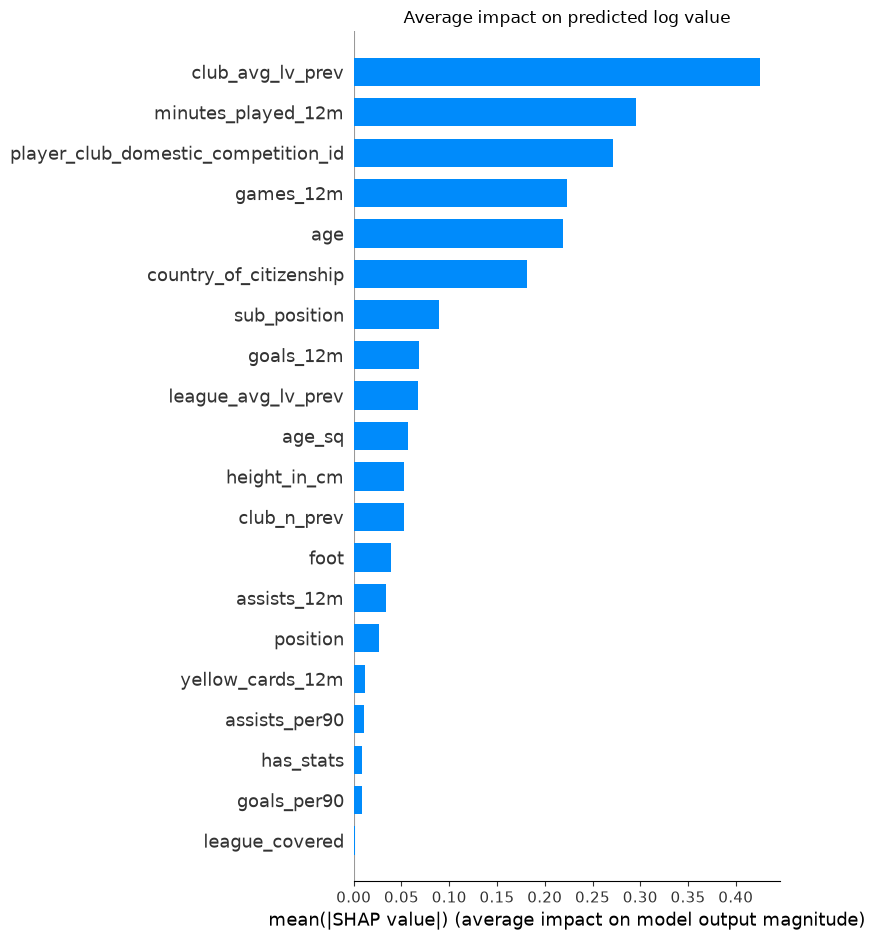

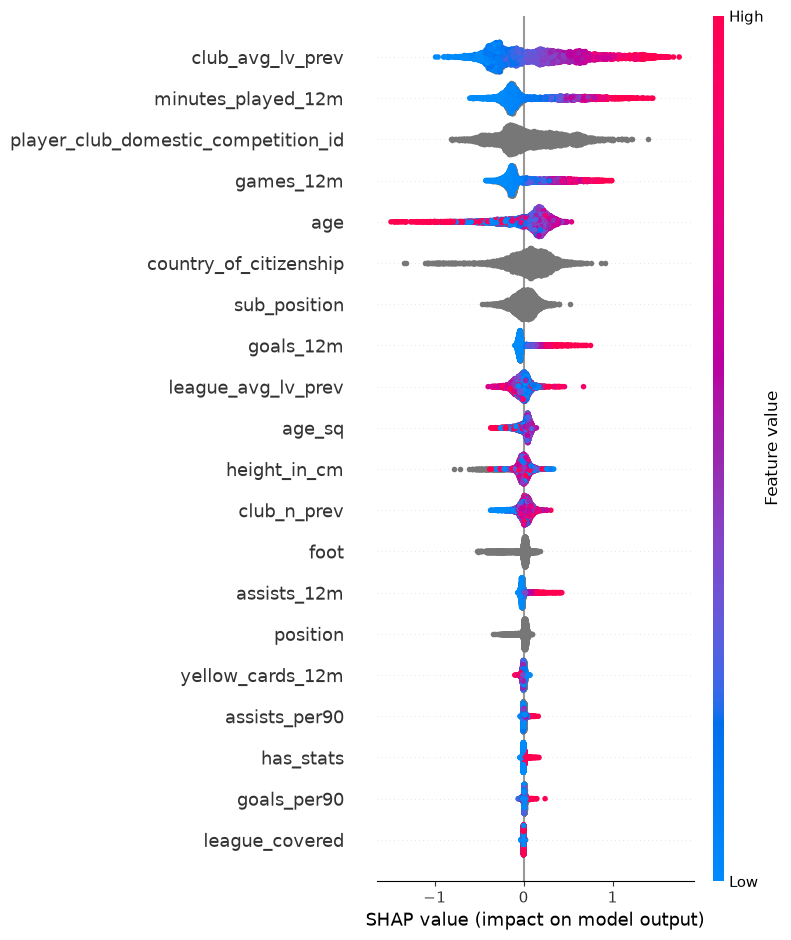

In [2]:
import os
os.makedirs("../reports", exist_ok=True)

# Explaining a sample of 5,000 rows because SHAP on all test rows would be slow
sample = Xte.sample(5000, random_state=42)
sv = shap.TreeExplainer(model).shap_values(sample)

shap.summary_plot(sv, sample, plot_type="bar", show=False)
plt.title("Average impact on predicted log value")
plt.tight_layout()
plt.savefig("../reports/shap_importance.png", dpi=150)
plt.show()

shap.summary_plot(sv, sample, show=False)  # each dot is one player; colour shows the feature's value
plt.tight_layout()
plt.savefig("../reports/shap_beeswarm.png", dpi=150)
plt.show()

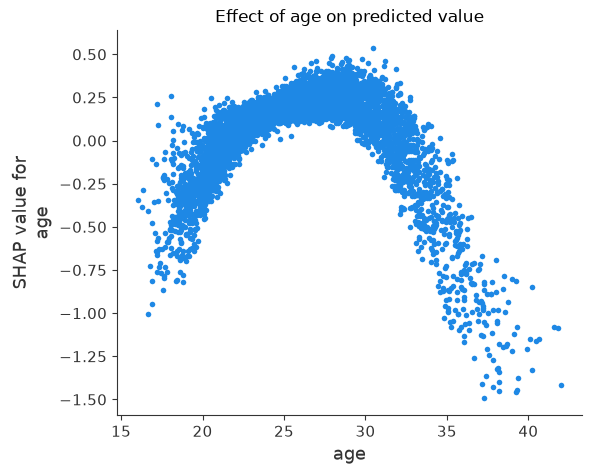

In [3]:
shap.dependence_plot("age", sv, sample, interaction_index=None, show=False)
plt.title("Effect of age on predicted value")
plt.savefig("../reports/shap_age.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
test["abs_pct_err"] = test["pct_err"].abs()
test["value_bucket"] = pd.cut(test["market_value_in_eur"], [0, 2.5e5, 1e6, 5e6, 2e7, 1e9],
                              labels=["<250k", "250k-1M", "1-5M", "5-20M", "20M+"])
test["age_group"] = pd.cut(test["age"], [14, 20, 23, 27, 31, 43],
                           labels=["15-20", "21-23", "24-27", "28-31", "32+"])

def summarize(by):
    # mean_log_err > 0 means overpredicting, < 0 means underpredicting
    return (test.groupby(by, observed=True)
            .agg(rows=("abs_pct_err", "size"),
                 median_abs_pct_err=("abs_pct_err", "median"),
                 mean_log_err=("err_log", "mean"))
            .round(2))

for col in ["value_bucket", "age_group", "position"]:
    print(summarize(col), "\n")

               rows  median_abs_pct_err  mean_log_err
value_bucket                                         
<250k         16123               66.86          0.57
250k-1M       25522               36.54          0.04
1-5M          16097               41.16         -0.30
5-20M          6233               41.35         -0.40
20M+           2329               28.61         -0.28 

            rows  median_abs_pct_err  mean_log_err
age_group                                         
15-20       5656               55.57         -0.20
21-23      14308               48.02         -0.05
24-27      20739               39.05          0.01
28-31      15391               37.28          0.09
32+        10210               40.79          0.23 

             rows  median_abs_pct_err  mean_log_err
position                                           
Attack      18545               43.62          0.03
Defender    21758               39.65          0.02
Goalkeeper   6779               47.77          0.05
M

In [5]:
names = pd.read_csv("../data/raw/players.csv", usecols=["player_id", "name"])
test = test.merge(names, on="player_id", how="left")

cols = ["name", "date", "age", "market_value_in_eur", "pred", "minutes_played_12m"]
big = test[test["market_value_in_eur"] >= 5e6]  # focusing on players worth 5M+, where misses matter most

print("Biggest underpredictions:")
print(big.nsmallest(10, "pct_err")[cols].round({"age": 0, "pred": 0}).to_string(index=False))
print("\nBiggest overpredictions:")
print(big.nlargest(10, "pct_err")[cols].round({"age": 0, "pred": 0}).to_string(index=False))

Biggest underpredictions:
             name       date  age  market_value_in_eur     pred  minutes_played_12m
   James Trafford 2025-03-28 22.0             20000000 286464.0                 0.0
    Marcel Reguła 2026-06-04 20.0              7000000 105060.0                 NaN
    Marcel Reguła 2026-03-26 19.0              7000000 110029.0                 NaN
   James Trafford 2025-05-27 23.0             22000000 351607.0                 0.0
      Love Arrhov 2025-11-19 18.0              5000000  80052.0                 NaN
Takehiro Tomiyasu 2025-10-21 27.0             16000000 281466.0                 NaN
       Jair Cunha 2025-06-06 20.0             13000000 295369.0                 NaN
    Junior Kroupi 2025-06-02 19.0             15000000 375720.0                 0.0
    Marcel Reguła 2025-12-08 19.0              5000000 133903.0                 NaN
 Christian Kofane 2025-06-24 19.0              5000000 135518.0                 NaN

Biggest overpredictions:
           name       da

In [6]:
# Looking at the club/league context behind the worst misses to see what is pulling the predictions
worst = pd.concat([big.nsmallest(10, "pct_err"), big.nlargest(10, "pct_err")])
out = worst[["name", "date", "current_club_name", "player_club_domestic_competition_id",
             "club_n_prev", "market_value_in_eur", "pred"]].copy()
out["club_avg_value_eur"] = np.expm1(worst["club_avg_lv_prev"]).round(-3)  # converting back to euros to compare
out["pred"] = out["pred"].round(-3)
print(out.to_string(index=False))

# Checking whether very low predictions for 5M+ players cluster in particular leagues
low = big.assign(pred_below_1M=big["pred"] < 1e6)
print("\nShare of 5M+ rows predicted below 1M:", round(low["pred_below_1M"].mean(), 3))
print(low.groupby("player_club_domestic_competition_id")["pred_below_1M"]
         .agg(["size", "mean"]).sort_values("mean", ascending=False).head(8).round(2))

             name       date             current_club_name player_club_domestic_competition_id  club_n_prev  market_value_in_eur       pred  club_avg_value_eur
   James Trafford 2025-03-28                    Burnley FC                                 GB1         67.0             20000000   286000.0           5199000.0
    Marcel Reguła 2026-06-04                Zaglebie Lubin                                 PL1         75.0              7000000   105000.0            351000.0
    Marcel Reguła 2026-03-26                Zaglebie Lubin                                 PL1         74.0              7000000   110000.0            366000.0
   James Trafford 2025-05-27                    Burnley FC                                 GB1         74.0             22000000   352000.0           5456000.0
      Love Arrhov 2025-11-19             IF Brommapojkarna                                 SE1         36.0              5000000    80000.0            287000.0
Takehiro Tomiyasu 2025-10-21            

In [7]:
# Checking whether a club's league label ever changes over time; if it never does, it is a snapshot, not history
known = df[df["player_club_domestic_competition_id"] != "UNK"]
changes = known.groupby("current_club_id")["player_club_domestic_competition_id"].nunique()
print("Clubs with more than one league label:", (changes > 1).sum(), "of", len(changes))

# Burnley was relegated and promoted several times in this period, so its label should change if it is historical
b = known[known["current_club_name"] == "Burnley FC"]
print(b.groupby(b["date"].dt.year)["player_club_domestic_competition_id"].agg(lambda s: s.value_counts().to_dict()))

Clubs with more than one league label: 0 of 796
date
2013                       {'GB1': 11, 'SC1': 2}
2014                       {'GB1': 28, 'SC1': 3}
2015              {'GB1': 39, 'SC1': 3, 'L1': 1}
2016    {'GB1': 43, 'L1': 2, 'BE1': 1, 'SC1': 1}
2017                       {'GB1': 50, 'BE1': 3}
2018             {'GB1': 75, 'BE1': 3, 'SA1': 1}
2019                       {'GB1': 52, 'BE1': 1}
2020                                 {'GB1': 52}
2021                                 {'GB1': 70}
2022                       {'GB1': 71, 'SC1': 1}
2023                                 {'GB1': 74}
2024                                 {'GB1': 72}
2025                                 {'GB1': 80}
2026                                 {'GB1': 40}
Name: player_club_domestic_competition_id, dtype: object


In [8]:
# Joining the club name from the ID, since current_club_name doesn't match the club at valuation time
clubs = pd.read_csv("../data/raw/clubs.csv", usecols=["club_id", "name"]).rename(
    columns={"club_id": "current_club_id", "name": "club_by_id"})
chk = worst.merge(clubs, on="current_club_id", how="left")
print(chk[["name", "date", "current_club_name", "club_by_id",
           "player_club_domestic_competition_id"]].to_string(index=False))

             name       date             current_club_name                        club_by_id player_club_domestic_competition_id
   James Trafford 2025-03-28                    Burnley FC                        Burnley FC                                 GB1
    Marcel Reguła 2026-06-04                Zaglebie Lubin                    Zaglebie Lubin                                 PL1
    Marcel Reguła 2026-03-26                Zaglebie Lubin                    Zaglebie Lubin                                 PL1
   James Trafford 2025-05-27                    Burnley FC                        Burnley FC                                 GB1
      Love Arrhov 2025-11-19             IF Brommapojkarna Idrottsföreningen  Brommapojkarna                                 SE1
Takehiro Tomiyasu 2025-10-21                  Without Club                               NaN                                 UNK
       Jair Cunha 2025-06-06 Botafogo de Futebol e Regatas                 S. A. F. Botafogo     